In [20]:
import os
from pathlib import Path
import tensorflow as tf
from matplotlib import pyplot as plt
from dataset import (
    remove_invalid_images,
    load_dataset,
    scale_dataset,
    split_dataset,
)
from model import build_model

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("MODELS_DIR:", MODELS_DIR)

PROJECT_ROOT: /Users/khengngok/PycharmProjects/DL4CVExercies/CNN/happy-sad-detector
DATA_DIR: /Users/khengngok/PycharmProjects/DL4CVExercies/CNN/happy-sad-detector/data
MODELS_DIR: /Users/khengngok/PycharmProjects/DL4CVExercies/CNN/happy-sad-detector/models


## **Optional Cleaning Step**

In [3]:
removed = remove_invalid_images(DATA_DIR)
print(f"Removed {len(removed)} invalid image(s).")

Removed 0 invalid image(s).


## **Load → Scale → Split**

In [5]:
data = load_dataset(DATA_DIR)
data = scale_dataset(data)

train, val, test = split_dataset(data)

print("Train batches:", len(train))
print("Validation batches:", len(val))
print("Test batches:", len(test))

Found 305 files belonging to 2 classes.
Train batches: 7
Validation batches: 2
Test batches: 1


## **Inspect One Batch**

In [10]:
batch = train.as_numpy_iterator().next()

print("Images:", batch[0].shape)
print("Labels:", batch[1].shape)
print("Pixel min:", batch[0].min())
print("Pixel max:", batch[0].max())

Images: (32, 256, 256, 3)
Labels: (32,)
Pixel min: 0.0
Pixel max: 1.0


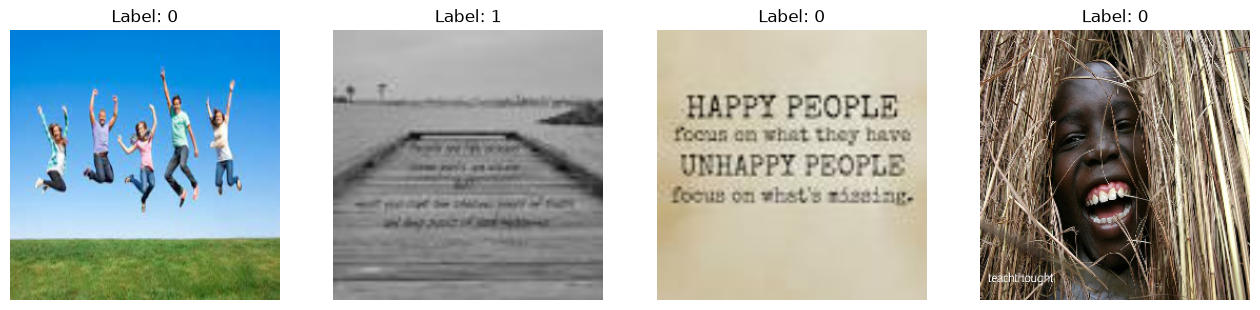

In [7]:
fig, axes = plt.subplots(ncols=4, figsize=(16, 4))

for idx, image in enumerate(batch[0][:4]):
    axes[idx].imshow(image)
    axes[idx].set_title(f"Label: {batch[1][idx]}")
    axes[idx].axis("off")

plt.show()

## **Build Model**

In [11]:
model = build_model()
model.summary()

Model: "happy_sad_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,696,625 (14.10 MB)

 Trainable params: 3,696,625 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

## **Compile**

In [13]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"],
)

## **Train**

In [14]:
history = model.fit(
    train,
    epochs=20,
    validation_data=val,
)

Epoch 1/20


/Users/khengngok/PycharmProjects/DL4CVExercies/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 333ms/step - accuracy: 0.4688 - loss: 0.8875 - val_accuracy: 0.5625 - val_loss: 0.6183
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 305ms/step - accuracy: 0.7500 - loss: 0.6168 - val_accuracy: 0.6406 - val_loss: 0.5533
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 334ms/step - accuracy: 0.8036 - loss: 0.4976 - val_accuracy: 0.8906 - val_loss: 0.4247
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 404ms/step - accuracy: 0.8438 - loss: 0.3939 - val_accuracy: 0.9062 - val_loss: 0.3208
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 464ms/step - accuracy: 0.9018 - loss: 0.3160 - val_accuracy: 0.9062 - val_loss: 0.2707
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 320ms/step - accuracy: 0.9286 - loss: 0.2188 - val_accuracy: 0.9375 - val_loss: 0.1472
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 350ms/step - accuracy: 0.9464 - loss: 0.1619 - val_accuracy: 0.9844 - val_loss: 0.1138
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 282ms/step - accuracy: 0.9732 - loss: 0.1099 - val_accuracy: 0.9688 - val_loss: 0.1157
Epo

## **Plot Loss**

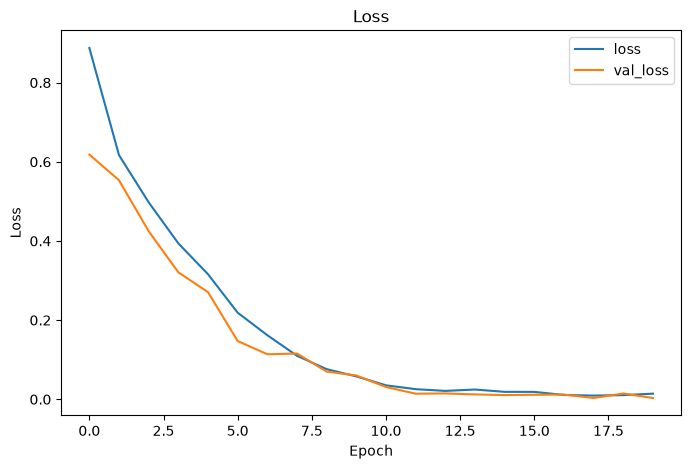

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## **Plot Accuracy**

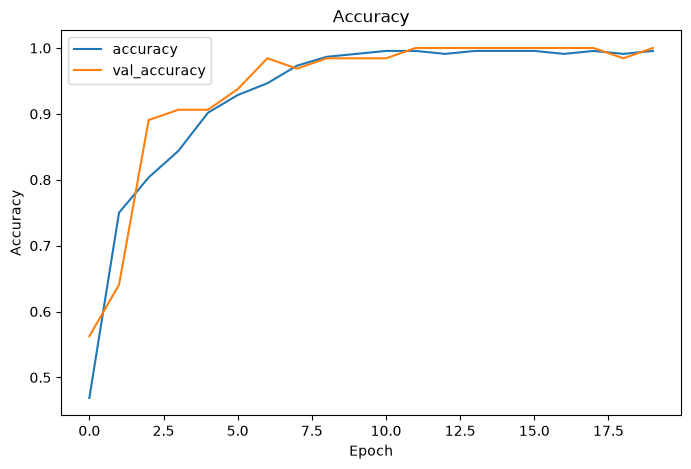

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## **Evaluate**

In [18]:
precision = tf.keras.metrics.Precision()
recall = tf.keras.metrics.Recall()
accuracy = tf.keras.metrics.BinaryAccuracy()

for x_batch, y_true in test:
    y_pred = model.predict(x_batch, verbose=0)

    precision.update_state(y_true, y_pred)
    recall.update_state(y_true, y_pred)
    accuracy.update_state(y_true, y_pred)

print("Precision:", float(precision.result()))
print("Recall:", float(recall.result()))
print("Accuracy:", float(accuracy.result()))

Precision: 1.0
Recall: 1.0
Accuracy: 1.0


2026-08-18 13:16:49.199965: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## **Save Model**

In [21]:
MODELS_DIR.mkdir(exist_ok=True)
MODEL_PATH = os.path.join(
        MODELS_DIR,
        'happysadmodel.h5'
    )
model.save(MODEL_PATH)

print("Saved to:", MODEL_PATH)

Saved to: /Users/khengngok/PycharmProjects/DL4CVExercies/CNN/happy-sad-detector/models/happysadmodel.h5


## **Load Model**

In [88]:
from pathlib import Path
from tensorflow.keras.models import load_model
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR = PROJECT_ROOT / "models"
MODEL_PATH = MODELS_DIR / "happysadmodel.h5"

new_model = load_model(MODEL_PATH)

[]

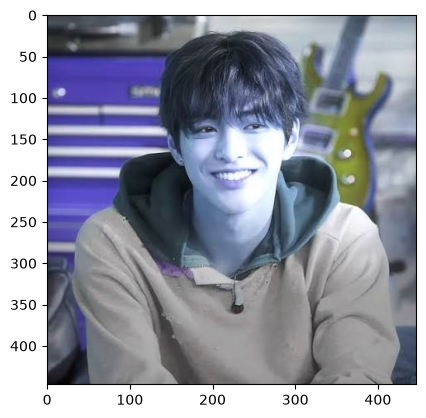

In [89]:
import cv2
img = cv2.imread("img.png")
plt.imshow(img)
plt.plot()

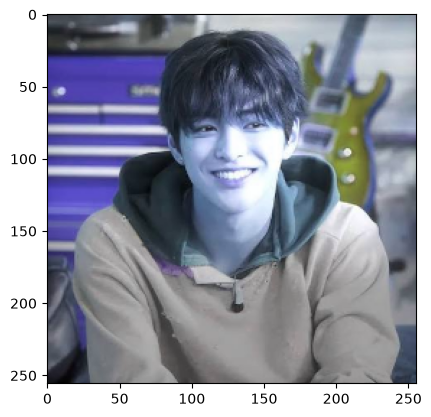

In [90]:
resize = tf.image.resize(img, (256,256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [91]:
input_image = np.expand_dims(resize/255, 0)

In [92]:
y_hat = new_model.predict(input_image)
y_hat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


array([[0.9899258]], dtype=float32)

In [94]:
if y_hat > 0.5:
    print("Keonho is Sad")
else:
    print("Keonho is Happy")

Keonho is Sad
